# 04 結果を図にする

03 で作った DESeq2 の結果を、図にします。

## 準備

下のセルを実行して、配布元から `samples.csv` をダウンロードします。

In [1]:
import warnings
warnings.filterwarnings("ignore")  # 計算には影響しない警告を表示しない

DATA_URL = "https://pub-fcc6b90fb32448a4b3b455e664df76f0.r2.dev/e2f1-rnaseq/v1/"
!wget -q -nc {DATA_URL}samples.csv
!ls -l samples.csv

-rw-r--r-- 1 root root 213 Oct 25 05:54 samples.csv


## 前のノートブックの結果を読み込む

03_DESeq2 の最後でダウンロードした `results_03.zip` を使います。下のセルを実行し、「ファイルを選択」を押して `results_03.zip` を選んでください。zip の中の `deseq2_results.csv`, `normalized_counts.csv`, `vst.csv` を、このノートブックで使います。

In [3]:
import zipfile
import os
from pathlib import Path

PREV_ZIP = "results_03.zip"
NEED = ['deseq2_results.csv', 'normalized_counts.csv', 'vst.csv']

if not all(Path(n).exists() for n in NEED):
    if Path(PREV_ZIP).exists():
        zipfile.ZipFile(PREV_ZIP).extractall()
    else:
        from google.colab import files
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall()

missing = [n for n in NEED if not Path(n).exists()]
if missing:
    print("見つからないファイルがあります:", missing)
    print("このセルをもう一度実行して zip を選び直すか、下の「zip が手元にないとき」のセルを実行してください。")
else:
    print("読み込みました:", NEED)

読み込みました: ['deseq2_results.csv', 'normalized_counts.csv', 'vst.csv']


### zip が手元にないとき

前のノートブックを最後まで実行できなかった人や、zip をなくした人だけ、下のセルを実行してください。教員が用意した `results_03.zip` をダウンロードして使います。

In [4]:
!wget -q -nc {DATA_URL}results_03.zip
zipfile.ZipFile(PREV_ZIP).extractall()
print("読み込みました:", [n for n in NEED if Path(n).exists()])

読み込みました: ['deseq2_results.csv', 'normalized_counts.csv', 'vst.csv']


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

res = pd.read_csv("deseq2_results.csv", index_col="gene")
normalized = pd.read_csv("normalized_counts.csv", index_col="gene")
vst = pd.read_csv("vst.csv", index_col="gene")
samples = pd.read_csv("samples.csv", index_col="sample").loc[normalized.columns]

COLOR = {"shControl": "#2F6FC4", "shPPP3CA": "#D9731A"}
UP, DOWN, NS = "#D9731A", "#2F6FC4", "#C9D1D9"

PADJ = 0.05
LFC = 1

## ボルケーノプロット

1つの点が1つの遺伝子です。横軸は変化の大きさ（log₂FC）、縦軸は確からしさ（−log₁₀ padj）で、上にある点ほど padj が小さい遺伝子です。padj < 0.05 かつ |log₂FC| ≥ 1 の遺伝子に色を付けます。橙は shPPP3CA で増えた遺伝子、青は減った遺伝子です。

`LABEL_GENES` に書いた遺伝子には、名前を添えます。

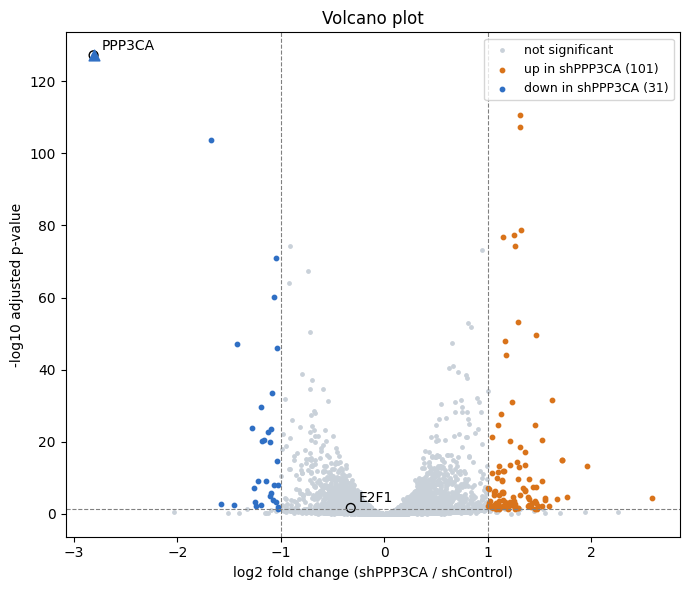

In [6]:
LABEL_GENES = ["PPP3CA", "E2F1"]

d = res.dropna(subset=["padj"]).copy()
d["neglog10_padj"] = -np.log10(d["padj"].clip(lower=1e-300))
# padj が極端に小さい遺伝子は、図の上端（▲）にそろえて描く
YMAX = d["neglog10_padj"].sort_values().iloc[-2] * 1.15
capped = d["neglog10_padj"] > YMAX
d.loc[capped, "neglog10_padj"] = YMAX
up = (d["padj"] < PADJ) & (d["log2FoldChange"] >= LFC)
down = (d["padj"] < PADJ) & (d["log2FoldChange"] <= -LFC)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(d.loc[~(up | down), "log2FoldChange"], d.loc[~(up | down), "neglog10_padj"], s=6, color=NS, label="not significant")
ax.scatter(d.loc[up, "log2FoldChange"], d.loc[up, "neglog10_padj"], s=10, color=UP, label=f"up in shPPP3CA ({up.sum()})")
ax.scatter(d.loc[down, "log2FoldChange"], d.loc[down, "neglog10_padj"], s=10, color=DOWN, label=f"down in shPPP3CA ({down.sum()})")
for g in LABEL_GENES:
    if g in d.index:
        x, y = d.loc[g, ["log2FoldChange", "neglog10_padj"]]
        ax.scatter(x, y, s=40, facecolors="none", edgecolors="black")
        ax.annotate(g, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=10)
ax.scatter(d.loc[capped, "log2FoldChange"], d.loc[capped, "neglog10_padj"], s=60, marker="^",
           color=[UP if v > 0 else DOWN for v in d.loc[capped, "log2FoldChange"]])
ax.axhline(-np.log10(PADJ), color="grey", lw=0.8, ls="--")
ax.axvline(LFC, color="grey", lw=0.8, ls="--")
ax.axvline(-LFC, color="grey", lw=0.8, ls="--")
ax.set_xlabel("log2 fold change (shPPP3CA / shControl)")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("Volcano plot")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
fig.savefig("volcano.png", dpi=150)
plt.show()

*PPP3CA* の padj は、ほかのどの遺伝子よりもずっと小さく、そのまま描くと図の上に大きく飛び出します。そこで、図の上端に ▲ で描いています。

## MA プロット

横軸に発現量の平均（baseMean の対数）、縦軸に log₂FC をとった図です。カウントの少ない遺伝子（左側）ほど、log₂FC が大きくぶれやすいことが分かります。

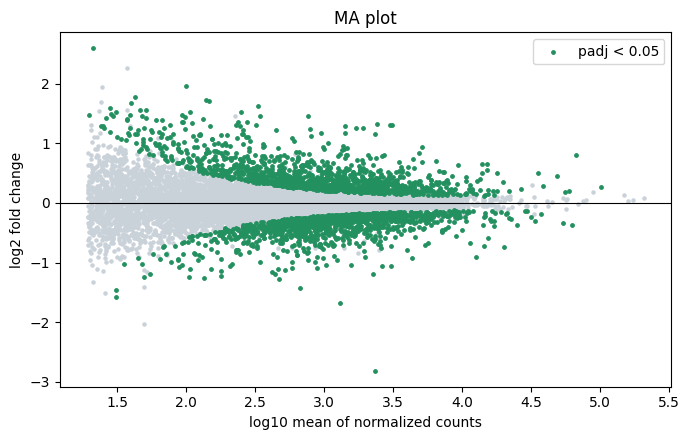

In [7]:
sig = d["padj"] < PADJ

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(np.log10(d.loc[~sig, "baseMean"]), d.loc[~sig, "log2FoldChange"], s=5, color=NS)
ax.scatter(np.log10(d.loc[sig, "baseMean"]), d.loc[sig, "log2FoldChange"], s=6, color="#23905F", label=f"padj < {PADJ}")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("log10 mean of normalized counts")
ax.set_ylabel("log2 fold change")
ax.set_title("MA plot")
ax.legend()
plt.tight_layout()
plt.show()

## 1つの遺伝子を6試料で見る

正規化したカウントを、試料ごとの点で示します。`GENE` を書き換えて、ボルケーノプロットで気になった遺伝子を見てみましょう。

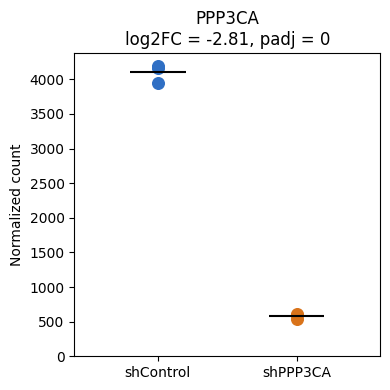

In [8]:
def plot_gene(gene):
    y = normalized.loc[gene]
    fig, ax = plt.subplots(figsize=(4, 4))
    for i, cond in enumerate(COLOR):
        s = samples.index[samples["condition"] == cond]
        ax.scatter([i] * len(s), y[s], s=70, color=COLOR[cond])
        ax.hlines(y[s].mean(), i - 0.2, i + 0.2, color="black")
    ax.set_xticks(range(len(COLOR)), list(COLOR))
    ax.set_xlim(-0.6, len(COLOR) - 0.4)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Normalized count")
    r = res.loc[gene]
    ax.set_title(f"{gene}\nlog2FC = {r['log2FoldChange']:.2f}, padj = {r['padj']:.2g}")
    plt.tight_layout()
    plt.show()


GENE = "PPP3CA"
plot_gene(GENE)

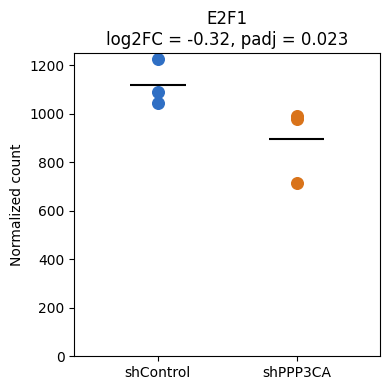

In [9]:
plot_gene("E2F1")

## 変化の大きい遺伝子のヒートマップ

padj が小さい順に上位30遺伝子を選び、VST の値をヒートマップにします。遺伝子ごとに平均を0、ばらつきを1にそろえた値（zスコア）で色を付けるので、赤はその遺伝子の中で高い試料、青は低い試料です。似た動きの遺伝子どうし、似た試料どうしが隣に来るように、行と列を並べ替えています。

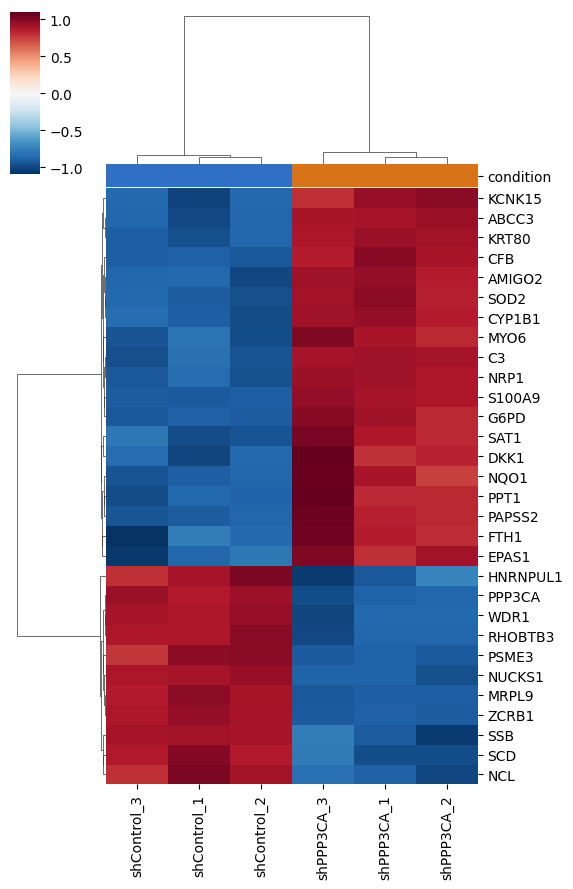

In [10]:
import seaborn as sns

N_TOP = 30
top = d.sort_values("padj").index[:N_TOP]
z = vst.loc[top]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)

g = sns.clustermap(z, cmap="RdBu_r", center=0, figsize=(6, 9),
                   col_colors=samples["condition"].map(COLOR), yticklabels=True)
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")
plt.show()

padj < 0.05 かつ |log₂FC| ≥ 1 の遺伝子の一覧を、`significant_genes.csv` に書き出します。Excel などで開けます。ボルケーノプロットの画像（`volcano.png`）は、上のセルで書き出してあります。

In [ ]:
significant = d[up | down].sort_values("log2FoldChange")
significant.to_csv("significant_genes.csv")
print(len(significant), "遺伝子")

## 結果をダウンロードする

下のセルを実行すると、ここまでの結果をまとめた `results_04.zip` がパソコンにダウンロードされます。次の 05_GSEA の最初でアップロードするので、保存した場所を覚えておいてください。

In [ ]:
import zipfile

OUT = "results_04.zip"
with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for name in ['counts_filtered.csv', 'vst.csv', 'deseq2_results.csv', 'normalized_counts.csv', 'significant_genes.csv', 'volcano.png']:
        z.write(name)
print(OUT, "に入れたファイル:", zipfile.ZipFile(OUT).namelist())

try:
    from google.colab import files
    files.download(OUT)
except ImportError:
    pass  # Colab 以外で実行したときは、手元のフォルダに保存される

次は **05_GSEA** に進みます。

[https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/05_GSEA.ipynb](https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/05_GSEA.ipynb)